# 图像增广
当训练数据集较少或者想要进一步扩大训练集规模时，可以采用图像增广技术，通过随机改变训练样本来减少模型对某些特定特征的依赖，有助于提升模型的**泛化能力**
* 随机裁剪图像，使目标物体出现在图像中的不同位置，减少模型对物体出现位置的依赖
* 调整图像的颜色、亮度来降低模型对颜色的敏感度

In [1]:
%matplotlib inline
import torch
from torch import nn
import torchvision
from torch.nn import functional as F
from d2l import torch as d2l
from PIL import Image
from matplotlib import pyplot as plt

## 常用图像增广方法
以下面这个尺寸为400 $ \times $ 500的图像为例

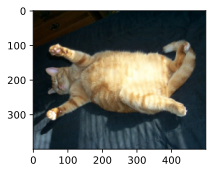

In [2]:
d2l.set_figsize()
img = Image.open("../李沐《动手学深度学习》\d2l-zh\pytorch\img\cat1.jpg")
plt.imshow(img) # [H, W, C]

预定义一个函数，方便观察随机图像增广的效果

In [3]:
def apply(img, aug, num_rows = 2, num_cols = 4, scale = 1.5):
    """
    aug：是图像增广方法函数
    """
    Y = [aug(img) for _ in range(num_rows * num_cols)]
    d2l.show_images(Y, num_rows, num_cols, scale = scale)

### 翻转
#### 左右翻转
这种图像增广方法通常不会改变对象类别

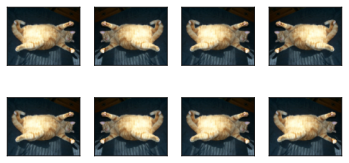

In [4]:
apply(img, torchvision.transforms.RandomHorizontalFlip())

#### 上下翻转

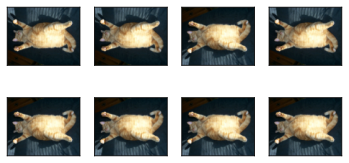

In [5]:
apply(img, torchvision.transforms.RandomVerticalFlip())

### 裁剪
之前已经介绍过汇聚层可以降低卷积层对目标位置的依赖性，同样，随机裁剪，使物体以不同比例出现在图像的不同位置，也可以降低模型对目标位置的依赖性

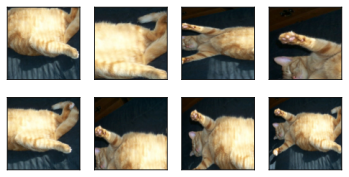

In [6]:
apply(img, torchvision.transforms.RandomResizedCrop((200, 200), scale = (0.1, 1), ratio = (0.5, 2)))

### 旋转

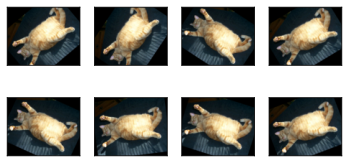

In [7]:
apply(img, torchvision.transforms.RandomRotation((-45, 60)))

### 仿射变换

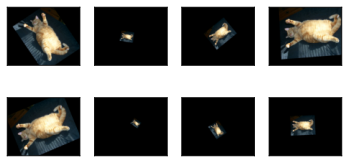

In [8]:
apply(img, torchvision.transforms.RandomAffine(degrees = (-45, 60), scale = (0.1, 1.0), translate = (0.1, 0.1), shear = 2))

### 透视畸变

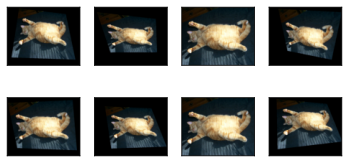

In [9]:
apply(img, torchvision.transforms.RandomPerspective())

### 颜色抖动

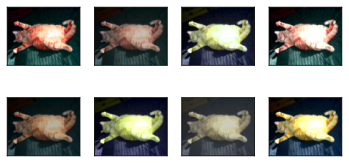

In [10]:
apply(img, torchvision.transforms.ColorJitter(0.4, 0.4, 0.4, 0.1))

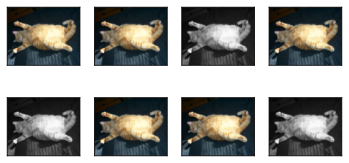

In [11]:
apply(img, torchvision.transforms.RandomGrayscale(p = 0.5))

### 模糊

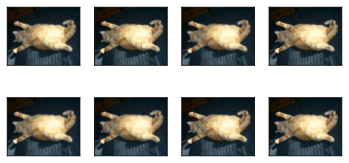

In [12]:
apply(img, torchvision.transforms.GaussianBlur(kernel_size = 11, sigma = (0.1, 2.5)))

### 曝光反转

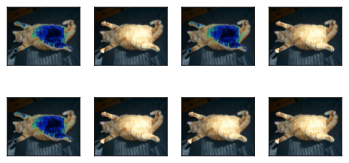

In [13]:
apply(img, torchvision.transforms.RandomSolarize(threshold = 180))

### 锐度

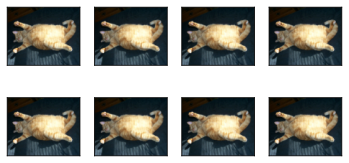

In [14]:
apply(img, torchvision.transforms.RandomAdjustSharpness(1.5))

### 遮挡

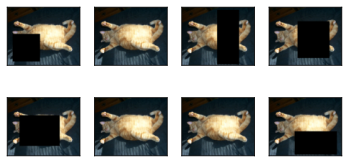

In [15]:
trans = torchvision.transforms.Compose([torchvision.transforms.ToTensor(), 
                                        torchvision.transforms.RandomErasing(p = 0.5),
                                        torchvision.transforms.ToPILImage()])
apply(img, trans)

### 自动增强

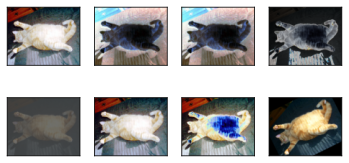

In [16]:
apply(img, torchvision.transforms.AutoAugment())

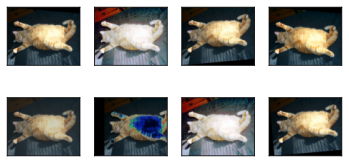

In [17]:
apply(img, torchvision.transforms.RandAugment())

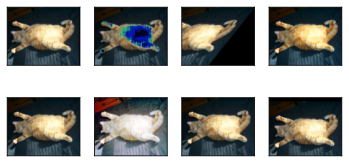

In [18]:
apply(img, torchvision.transforms.TrivialAugmentWide())

## transforms全部图像增广方法
> 分为：**PIL 图像变换**、**Tensor 变换**；注意：一部分只能作用 PIL，一部分只能作用 Tensor。
>  
> Compose 把多个变换串起来：`transforms.Compose([...])`

### 1. 随机几何变换（空间变换，最常用）

| 变换                                                         | 作用                                                 |
| ------------------------------------------------------------ | ---------------------------------------------------- |
| `RandomHorizontalFlip(p=0.5)`                                | 随机**左右水平翻转**，概率 p；p=1 必翻转             |
| `RandomVerticalFlip(p=0.5)`                                  | 随机**上下垂直翻转**                                 |
| `RandomResizedCrop(size, scale=(0.08,1.0), ratio=(0.75,1.333))` | 随机裁剪 + resize 到目标 size；scale是相对于原图裁剪的缩放系数，面积比例在0.08~1.0，ratio是宽高比，随机从0.75~1.333选取 |
| `RandomCrop(size, padding=None)`                             | 随机裁剪；可设置 padding 先外扩再裁                  |
| `CenterCrop(size)`                                           | 中心裁剪，**确定性，不是增广**                       |
| `RandomRotation(degrees, expand=False)`                      | 随机旋转，degrees 角度范围，expand是False时会自动裁剪超出图像尺寸的部分|
| `RandomAffine(degrees, translate = (a, b), scale, shear)`             | 随机仿射变换：旋转、平移、缩放、剪切, a是横向最大偏移占图像比例，b是纵向最大偏移占图像比例|
| `RandomPerspective(distortion_scale=0.5, p=0.5)`             | 随机透视畸变     

### 2. 颜色抖动（像素色彩，不改变形状）
| 变换                                                 | 作用                                               |
| ---------------------------------------------------- | -------------------------------------------------- |
| `ColorJitter(brightness, contrast, saturation, hue)` | 随机抖动：亮度、对比度、饱和度、色调；分类任务高频，传入brightness = 0.4获得的亮度范围是[1-0.4, 1+0.4],contract和saturation同理，hue传入0.1后色调取[-0.1, 0.1] |
| `RandomGrayscale(p=0.1)`                             | 概率 p 转为单通道灰度图，输出依旧 3 通道           |
| `Grayscale(num_output_channels=1)`                   | 确定性转灰度，不是增广                             |


#### 2.1 ColorJitter 底层原理

> ColorJitter 不会直接全部在 RGB 空间粗暴改数值，其中一部分变换会转到 HSV（色相‑饱和度‑明度）色彩空间做运算，做完再转回 RGB。

**RGB**：红、绿、蓝；三个通道代表颜色。

**HSV 三个分量：**
- **H Hue 色相**：是什么颜色（红、橙、黄、绿、青、蓝、紫），角度，$0\sim1$（对应 $0^\circ\sim360^\circ$）
- **S Saturation 饱和度**：颜色浓淡；0 = 灰度，1 = 颜色最鲜艳
- **V Value 明度 (亮度)**：图像明暗

> 注意：ColorJitter 的 `brightness`、`contrast` **不是操作 V 通道！**
> - `brightness`、`contrast`：在 RGB 空间运算
> - `saturation`、`hue`：转到 HSV 空间，修改 S、H，再转回 RGB

##### 2.1.1 brightness（亮度）
$$
\text{new\_rgb} = \text{rgb} \times \text{factor}
$$
`factor` 随机采样 $[1‑b,1+b]$。
全部 RGB 通道整体乘以同一个系数。
- $\text{factor}>1$：整体变亮
- $\text{factor}<1$：整体变暗

简单粗暴，所有像素同步放大缩小；有可能超出 $0‑255$，内部会做 `clip` 截断。

##### 2.1.2 contrast（对比度）
$$
\text{new\_rgb}= (\text{rgb}‑\text{mean}) \times \text{factor} + \text{mean}
$$
`factor` 采样 $[1‑c,1+c]$。
- $\text{mean}$：整张图所有像素的 RGB 均值
- $\text{factor}>1$：像素离均值更远 → 对比度变强，明暗差距拉大
- $\text{factor}<1$：全部向均值靠拢 → 图片灰蒙蒙，对比度降低

`brightness` 和 `contrast` 直接在 RGB 做，不进入 HSV。

##### 2.1.3 saturation 饱和度（进入 HSV）
1. $\text{RGB} \rightarrow \text{HSV}$
2. 只对 S（饱和度通道）做乘法：
$$
S_{new}=S \times \text{factor}
$$
`factor` 采样 $[1‑s,1+s]$
- $\text{factor}\rightarrow0$：S 趋近 0，图片变灰度
- $\text{factor}>1$：颜色更浓更艳
3. `clip` 将 S 限制在 $[0,1]$
4. $\text{HSV} \rightarrow \text{RGB}$

H 保持不变，只改颜色浓淡，不改变是什么颜色。

##### 2.1.4 hue 色调（色相，最特殊）
hue 代表角度，**不能做乘法，只能加法偏移**！
1. $\text{RGB} \rightarrow \text{HSV}$
2. H 通道取值范围 $[0,1]$，等价 $0^\circ\sim360^\circ$
3. 加上随机偏移量 $\delta$，$\delta \in [-hue, hue]$
$$
H_{new} = (H+\delta) \bmod 1
$$
模 1 运算：超过 1 就绕回 0，小于 0 绕回 1（色相环形，红‑橙‑黄‑绿‑蓝‑紫循环）。
4. S、V 保持不变
5. $\text{HSV} \rightarrow \text{RGB}$

例子：
- `hue=0.1`：色相最多偏移 $0.1 \times 360^\circ = 36^\circ$。
- hue 最大允许 0.5，偏移 $180^\circ$，颜色完全反转。

> 补充：torchvision 的 ColorJitter 内部会**随机打乱 brightness / contrast / saturation / hue 的执行顺序**，因此相同随机系数下，不同运算顺序输出结果也会不同。


### 3. 模糊、噪声、滤波
| 变换                                             | 作用                              |
| ------------------------------------------------ | --------------------------------- |
| `GaussianBlur(kernel_size, sigma)`               | 随机高斯模糊；SimCLR 对比学习常用 |
| `RandomSolarize(threshold, p=0.5)`               | 随机曝光反转，超过阈值像素取反    |
| `RandomAdjustSharpness(sharpness_factor, p=0.5)` | 随机调节图像锐度                  |



#### 3.1 GaussianBlur 高斯模糊原理

高斯模糊本质：用**二维高斯分布生成卷积核**，对图像做卷积运算，属于**低通滤波**。把图像尖锐的高频细节（边缘、噪点）抹平，图像变柔和。

##### 3.1.1 二维高斯公式
$$
G(x,y)=\frac{1}{2\pi\sigma^2}\exp\left(-\frac{x^2+y^2}{2\sigma^2}\right)
$$
- $(x,y)$：相对于卷积核中心的坐标
- $\boldsymbol{\sigma}$：标准差，就是代码中的 `sigma`
  - $\sigma$ 越大：高斯分布越“矮胖”，周边权重变大 → 模糊越强
  - $\sigma$ 越小：越尖锐，接近原图

##### 3.1.2 kernel_size（核大小）
卷积核窗口尺寸，**必须奇数**（才有中心点），如 3、5、7。
> 经验：核要足够大，要覆盖高斯分布绝大部分权重，一般 $kernel\_size \ge 6\sigma$。
> 如果核太小，相当于截断高斯分布，模糊效果变差。

举例：`kernel_size=5`，就是一个 $5\times5$ 的权重矩阵，中心权重最大，越往四周权重越小。

示例 3×3 高斯核（σ≈1）示意：
$$
\begin{bmatrix}
0.075 & 0.124 & 0.075 \\
0.124 & 0.204 & 0.124 \\
0.075 & 0.124 & 0.075
\end{bmatrix}
$$
核所有权重求和等于1，保证图像整体亮度不变。

##### 3.1.3 卷积计算过程
滑动 $kernel\_size\times kernel\_size$ 窗口逐像素遍历图像：
1. 取图像局部窗口像素；
2. 和高斯核权重**对应位置相乘再求和**，作为输出中心像素；
3. 窗口滑动到下一个像素，重复。

> 特点：
> - 中心像素权重最高，周边像素贡献逐步降低；
> - 不是简单平均模糊（均值滤波），是加权平均，中心更重要。

##### 3.1.4 torchvision 中两个参数行为
- `kernel_size`：固定卷积窗口大小，不可随机。
- `sigma=(0.1,2.0)`：每次增强，在区间随机采样一个 $\sigma$，生成不同强度的高斯核做卷积。
> ❗注意：这里只是**随机模糊强度，不是有概率跳过模糊**，该变换没有p，每次一定做模糊。想要概率执行需要套`RandomApply`。

##### 3.1.5 为什么做数据增强要用高斯模糊
图像中很多虚假高频噪声（纹理噪点），模型容易记住这些伪特征。
高斯模糊抑制高频，强迫模型学习物体更本质的中低频特征。
> SimCLR/MoCo 对比学习大量使用；普通监督分类很少开，太强模糊会丢失判别信息。



### 4. 擦除类 **只支持 Tensor！不能给 PIL**

> 注意！这一组必须放在`ToTensor()`之后！

  | 变换 | 作用 | 
 |---|---|
 |`RandomErasing(p=0.5, scale=(0.02,0.33), ratio=(0.3,3.3))`| 随机矩形区域置 0，模拟遮挡；防止过拟合 |

### 5. 确定性预处理（不属于增强，只是预处理）
```python
Resize(size)             # 缩放
ToTensor()               # PIL → Tensor [0,1], CHW
Normalize(mean, std)     # 归一化，必须Tensor
Pad(padding)             # 填充

```

### 6. 自动增广系列（AutoAugment 系列）
| 变换                                             | 说明                                     |
| ------------------------------------------------ | ---------------------------------------- |
| `AutoAugment(policy=AutoAugmentPolicy.IMAGENET)` | 论文 AutoAugment，预定义搜索好的增强策略 |
| `RandAugment(num_ops, magnitude)`                | RandAugment，简单高效，现在非常常用      |
| `TrivialAugmentWide()`                           | TrivialAugment，超简单，少超参           |

## 训练CIFAR-10

100.0%


Extracting ../data\cifar-10-python.tar.gz to ../data


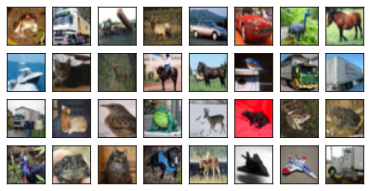

In [22]:
import ssl
ssl._create_default_https_context = ssl._create_unverified_context
all_images = torchvision.datasets.CIFAR10(train=True, root="../data",
                                          download=True)
d2l.show_images([all_images[i][0] for i in range(32)], 4, 8, scale=0.8);